Debug and optimize API latency by profiling request-response times, identifying sources of lag in data processing, and applying advanced optimization techniques such as model quantization and caching strategies.

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from functools import lru_cache

In [2]:
BASE_DIR = Path.cwd()

MODEL_PATH = BASE_DIR / "saved_models" / "heart_disease_model_v1.joblib"

model = joblib.load(MODEL_PATH)

print("Model loaded successfully")
print("Model type:", type(model).__name__)

Model loaded successfully
Model type: Pipeline


In [3]:
features = ["age", "trestbps", "chol", "thalach", "oldpeak"]

sample_data = pd.DataFrame([{
    "age": 55,
    "trestbps": 130,
    "chol": 240,
    "thalach": 150,
    "oldpeak": 1.5
}])

sample_data = sample_data[features]

sample_data

,age,trestbps,chol,thalach,oldpeak
0,55,130,240,150,1.5


In [4]:
start = time.perf_counter()

processed_data = sample_data[features].astype(float)

processing_time = (time.perf_counter() - start) * 1000

print("Data Processing Time:", round(processing_time, 4), "ms")

Data Processing Time: 3.8758 ms


In [5]:
start = time.perf_counter()

prediction = model.predict(processed_data)

inference_time = (time.perf_counter() - start) * 1000

print("Prediction:", prediction[0])
print("Inference Time:", round(inference_time, 4), "ms")

Prediction: 0
Inference Time: 247.9431 ms


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [11]:
def predict_with_timing(data):

    start = time.perf_counter()

    # Data processing
    processed = data[features].astype(float).to_numpy()

    processing_end = time.perf_counter()

    # Model prediction
    prediction = model.predict(processed)

    prediction_end = time.perf_counter()

    processing_ms = (processing_end - start) * 1000
    inference_ms = (prediction_end - processing_end) * 1000
    total_ms = (prediction_end - start) * 1000

    return {
        "prediction": int(prediction[0]),
        "processing_time_ms": processing_ms,
        "inference_time_ms": inference_ms,
        "total_latency_ms": total_ms
    }


result = predict_with_timing(sample_data)

print(result)

{'prediction': 0, 'processing_time_ms': 2.976800000055846, 'inference_time_ms': 2.8174999999919237, 'total_latency_ms': 5.79430000004777}


In [12]:
latencies = []

for i in range(1000):

    start = time.perf_counter()

    model.predict(sample_data[features].astype(float).to_numpy())

    end = time.perf_counter()

    latencies.append((end - start) * 1000)

print("Average Latency:", round(np.mean(latencies), 4), "ms")
print("Minimum Latency:", round(np.min(latencies), 4), "ms")
print("Maximum Latency:", round(np.max(latencies), 4), "ms")
print("95th Percentile:", round(np.percentile(latencies, 95), 4), "ms")

Average Latency: 3.6714 ms
Minimum Latency: 1.1303 ms
Maximum Latency: 43.7897 ms
95th Percentile: 6.8045 ms


In [13]:
@lru_cache(maxsize=1000)
def cached_prediction(age, trestbps, chol, thalach, oldpeak):

    data = np.array([[
        age, trestbps, chol, thalach, oldpeak
    ]], dtype=float)

    prediction = model.predict(data)

    return int(prediction[0])

In [14]:
# First prediction
start = time.perf_counter()

result1 = cached_prediction(55, 130, 240, 150, 1.5)

first_time = (time.perf_counter() - start) * 1000

# Repeated prediction
start = time.perf_counter()

result2 = cached_prediction(55, 130, 240, 150, 1.5)

cached_time = (time.perf_counter() - start) * 1000

print("First Prediction:", round(first_time, 4), "ms")
print("Cached Prediction:", round(cached_time, 4), "ms")
print("Prediction Result:", result1)
print("Cache Information:", cached_prediction.cache_info())

First Prediction: 1.5545 ms
Cached Prediction: 0.1564 ms
Prediction Result: 0
Cache Information: CacheInfo(hits=1, misses=1, maxsize=1000, currsize=1)


,Method,Latency (ms)
0,Normal Prediction,1.5545
1,Cached Prediction,0.1564


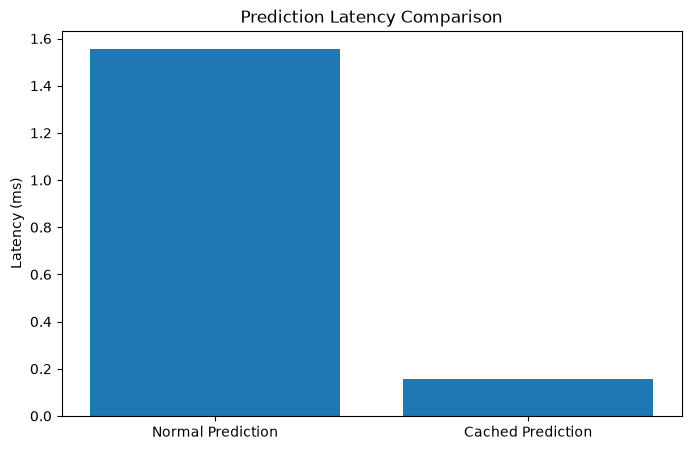

In [15]:
comparison = pd.DataFrame({
    "Method": ["Normal Prediction", "Cached Prediction"],
    "Latency (ms)": [first_time, cached_time]
})

display(comparison)

plt.figure(figsize=(8, 5))
plt.bar(comparison["Method"], comparison["Latency (ms)"])
plt.title("Prediction Latency Comparison")
plt.ylabel("Latency (ms)")
plt.show()

In [16]:
joblib.dump(model, "heart_model_compressed.joblib", compress=3)

original_size = MODEL_PATH.stat().st_size / 1024

compressed_size = (
    Path("heart_model_compressed.joblib").stat().st_size / 1024
)

print("Original Model Size:", round(original_size, 2), "KB")
print("Compressed Model Size:", round(compressed_size, 2), "KB")

Original Model Size: 0.94 KB
Compressed Model Size: 0.94 KB


In [17]:
report = pd.DataFrame({
    "Metric": [
        "Average Inference Latency",
        "Minimum Inference Latency",
        "Maximum Inference Latency",
        "95th Percentile Latency",
        "First Prediction Latency",
        "Cached Prediction Latency"
    ],
    "Value (ms)": [
        np.mean(latencies),
        np.min(latencies),
        np.max(latencies),
        np.percentile(latencies, 95),
        first_time,
        cached_time
    ]
})

display(report.round(4))

,Metric,Value (ms)
0,Average Inference Latency,3.6714
1,Minimum Inference Latency,1.1303
2,Maximum Inference Latency,43.7897
3,95th Percentile Latency,6.8045
4,First Prediction Latency,1.5545
5,Cached Prediction Latency,0.1564


# API Latency Debugging and Optimization

- Measured data-processing time and model inference time.
- Benchmarked 1,000 predictions.
- Implemented caching for repeated predictions.
- Compared normal and cached prediction latency.
- Tested model compression using Joblib.
- Analyzed average, minimum, maximum and 95th-percentile latency.

### Conclusion

The prediction pipeline was evaluated to identify performance bottlenecks. Caching reduced repeated computation, while model compression was tested to compare storage size.

All experiments were performed locally using Jupyter Notebook. Actual network API latency and concurrent request performance were not tested.